# Spark, live and visual

Day 3, before Lab 3.2 · Colab (or WSL / Linux / macOS with Java 17+). DuckDB and Polars ran every lab so far on one
machine. This walkthrough shows what changes when the work is spread over a cluster: how Spark splits it, plans it,
moves data between machines, and where that goes wrong.

**Rhythm:** each section gives **the idea** in two or three sentences, then **the picture** (a step-by-step player:
click **Next ▶** or **▶ Play**), then **the proof**: real Spark code on Qafila's data. Most pictures are drawn from
what Spark just returned. 🤔 = predict before you run the cell.

**Exercises (✏️):** uncomment the template (`Ctrl+/`), replace every `___`, delete the two `YOUR CODE HERE` lines,
then run the cell and the check after it (✅ = right). Answers: `solutions/tools/spark.ipynb`.

**In class:** 🎯 walked, with minutes (core ≈ 25') · ➕ at your own pace, like the ✏️ exercises not done in class.

| | Section | The one idea | In class |
|---|---|---|---|
| 0 | The problem: do you need a cluster? | scale up first; scale out when you must | 🎯 3' |
| 1 | Why Spark: driver, executors, cores | split the data, send the work to many machines | 🎯 2' |
| 2 | Partitions are tasks | one partition on one core is one task | 🎯 3' |
| 3 | Lazy evaluation | transformations plan, actions run | 🎯 3' |
| 4 | Narrow vs. wide | a `groupBy` has to move rows: the shuffle | 🎯 5' |
| 5 | Joins | broadcast the small side, shuffle the big ones | 🎯 4' |
| 6 | Skew | one key, one huge task | 🎯 2' |
| 7 | Writing | one file per task | 🎯 2' |
| 8 | Back to the map | what Spark is for, and its neighbours | 🎯 1' |

⚠️ Run this on **Colab** (Spark 4 needs Java 17+; on Colab the first Spark cell installs it, about a minute). Native
Windows can't run it; WSL can.

🎓 **Instructor notes** (solution notebook only)

- Start the first Spark cell (§1) while you introduce §0: on Colab it installs Java, about a minute.
- Open the Spark UI tab in §1 and keep it on screen; refresh it after each action.
- Core ≈ 25' (🎯 in the contents), without the two exercises. §6 shows skew only: Lab 3.2 does the salting.
- Lab 3.2 does pruning, broadcast timing, salting and the small-files count: don't do those here.

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/SDAIAAcademy/data-engineering.git"
    if not Path("/content/data-engineering").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/data-engineering"], check=True)
    os.chdir("/content/data-engineering/labs")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
else:
    while not Path("de_utils.py").exists() and Path.cwd() != Path.cwd().parent:
        os.chdir("..")  # tools/ and solutions/tools/ notebooks run from labs/
sys.path.insert(0, os.getcwd())

import de_utils as U
import de_viz as V
U.ensure_data()
print("data:", U.RAW, "| quick mode:", U.QUICK)

data: /mnt/c/Users/nayef/Desktop/courses/data-engineering/labs/data/raw | quick mode: False


You are here: Spark **transforms** at scale: the same work as DuckDB or Polars, spread over a cluster when one
machine is not enough.

In [2]:
V.platform_map(tool="spark")

A small "data lake" for Spark: DuckDB exports the raw tables to Parquet, with `orders` in daily folders
(`order_date=2026-09-23/`), as a nightly ingestion job would land them.

In [3]:
LAKE = U.lab_dir("tools_spark", reset=True)
con = U.connect(U.build_warehouse())
con.sql(f"""COPY (SELECT * EXCLUDE (_loaded_at), created_at[:10]::DATE AS order_date FROM raw.orders)
            TO '{(LAKE / "orders").as_posix()}' (FORMAT parquet, PARTITION_BY (order_date))""")
for t in ["order_items", "stores", "products"]:
    con.sql(f"""COPY (SELECT * EXCLUDE (_loaded_at) FROM raw.{t}) TO '{(LAKE / t).as_posix()}.parquet'
                (FORMAT parquet, ROW_GROUP_SIZE 20000)""")
print("order folders:", len(list((LAKE / "orders").iterdir())), "| parquet files:", U.count_files(LAKE))

order folders: 61 | parquet files: 64


## 0 · The problem: do you need a cluster?

**Scale up first; scale out when you must.** One machine is enough for most tables: DuckDB and Polars handle hundreds
of gigabytes on a large VM, with no cluster to run, and every lab so far ran on a laptop. A cluster earns its cost
when:
- a single job reads **terabytes**, more than one machine can scan in the time you have;
- the work must finish inside a **window** (say 01:00 to 05:00) that one machine can't meet;
- **many teams** share one platform, its data and its compute.

And you will meet Spark anyway: Databricks, AWS EMR and Glue, Google Dataproc and Microsoft Fabric all run it, and
many existing pipelines are written in it. Spark 4 (2025–26) brought ANSI SQL by default, a `VARIANT` type for JSON,
Spark Connect (a thin client talking to a remote cluster) and Arrow everywhere between the JVM and Python.

The data here fits on a laptop many times over; we run Spark on it to **see** how a cluster splits the work.

## 1 · Why Spark: one driver, many executors

**The idea.** One machine reads data at a fixed speed, and the data keeps growing. Spark splits the data into pieces
and sends the work to many machines. The **driver** plans the work, the **executors** do it, and each executor
**core** works on one piece at a time.

Start Spark first (on Colab this installs Java, so let it run while we look at the picture).

In [4]:
from pyspark.sql import functions as F

spark = U.get_spark()
print("Spark", spark.version, "| master:", spark.sparkContext.master,
      "| cores:", spark.sparkContext.defaultParallelism, "| shuffle partitions:", spark.conf.get("spark.sql.shuffle.partitions"))
print("Spark UI:", spark.sparkContext.uiWebUrl)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/21 21:41:05 WARN Utils: Your hostname, Naif, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/10/21 21:41:05 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/21 21:41:07 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0 | master: local[2] | cores: 2 | shuffle partitions: 8
Spark UI: http://10.255.255.254:4040


**The picture.** Step through it: the problem, then the pieces of a cluster, then what happens when you run something.

In [5]:
V.spark_cluster(spark.sparkContext.master, spark.sparkContext.defaultParallelism)

The words you'll read in the UI and in every Spark error message:

| Word | Is |
|---|---|
| **driver** | your program: builds and optimizes the plan, schedules the tasks |
| **cluster manager** | hands out machines: YARN, Kubernetes, standalone, or a managed service |
| **executor** | a JVM process on a worker machine; runs tasks on its cores, can cache data |
| **job** | the work one **action** starts (`count`, `show`, `write`, `collect`) |
| **stage** | a run of work with no shuffle; each shuffle starts a new stage |
| **task** | one stage on one **partition**; tasks run in parallel on executor cores |

Here everything runs in one process (`local[2]`): driver and executors share this machine. The code is the same on a
1,000-node cluster; only the master changes.

**The proof** is the **Spark UI**: Jobs → Stages → Tasks, with time and rows per task. It's where you debug real jobs.
On Colab, this cell opens it in a new browser tab (keep it open and refresh it after each action below).

In [6]:
if IN_COLAB:
    from google.colab import output
    output.serve_kernel_port_as_window(4040, path="/jobs/")
else:
    print("open", spark.sparkContext.uiWebUrl, "in your browser")

open http://10.255.255.254:4040 in your browser


## 2 · Partitions are tasks

**The idea.** Spark splits every dataset into **partitions**. One partition processed on one core is one **task**.
Input files are cut into splits of at most `spark.sql.files.maxPartitionBytes` (128 MB by default). Our
`order_items` file is only 1.5 MB, so we lower the limit to 256 KB to see several tasks on a laptop.

🤔 With 2 cores, how many partitions should we hope for: 1, 2, or more?

In [7]:
spark.conf.set("spark.sql.files.maxPartitionBytes", "256k")
items = spark.read.parquet((LAKE / "order_items.parquet").as_posix())
orders = spark.read.parquet((LAKE / "orders").as_posix())
products = spark.read.parquet((LAKE / "products.parquet").as_posix())
stores = spark.read.parquet((LAKE / "stores.parquet").as_posix())

parts = items.groupBy(F.spark_partition_id().alias("partition")).count().orderBy("partition").toPandas()
print("order_items partitions:", items.rdd.getNumPartitions())
parts

order_items partitions: 6


,partition,count
0,0,40960
1,1,20480
2,2,40960
3,3,20480
4,4,40960
5,5,8705


**The picture**, drawn from the counts above: the file is cut into partitions, then each partition runs as a task on
whichever core is free.

In [8]:
V.partitions(parts, cores=spark.sparkContext.defaultParallelism)

With 2 cores, two tasks run at a time; on a cluster with 400 cores, 400 do. So we want **more partitions than cores**
(every core stays busy), but not millions of tiny ones (each task has a fixed start-up cost).

✏️ **Exercise 1** · Double the split size to 512 KB and read `order_items` again.
- **Result:** `n_512`, the number of partitions of the new read.
- **Check yourself:** fewer partitions than at 256 KB, and the same rows.

In [9]:
# Template:
# spark.conf.set("spark.sql.files.maxPartitionBytes", "___")
# items_512 = spark.read.parquet((LAKE / "order_items.parquet").as_posix())
# n_512 = items_512.rdd.___()
spark.conf.set("spark.sql.files.maxPartitionBytes", "512k")
items_512 = spark.read.parquet((LAKE / "order_items.parquet").as_posix())
n_512 = items_512.rdd.getNumPartitions()
print("partitions at 256 KB:", items.rdd.getNumPartitions(), "| at 512 KB:", n_512)

partitions at 256 KB: 6 | at 512 KB: 3


In [10]:
U.check(n_512 < items.rdd.getNumPartitions(), "bigger splits, fewer partitions: fewer, longer tasks")
U.check(items_512.count() == items.count(), "the same rows, cut differently")
spark.conf.set("spark.sql.files.maxPartitionBytes", "256k")   # back to the setting the rest of the notebook uses

✅ bigger splits, fewer partitions: fewer, longer tasks


✅ the same rows, cut differently



## 3 · Lazy evaluation: transformations plan, actions run

**The idea.** Transformations (`filter`, `withColumn`, `select`, `join`, `groupBy`) don't run anything: they add a
step to a **plan**. Only an **action** (`count`, `show`, `collect`, `write`) runs the plan as one or more **jobs**.

🤔 We filter, compute and select. How many Spark **jobs** does that run? And the `count()` after it?

In [11]:
jobs = lambda: len(spark.sparkContext.statusTracker().getJobIdsForGroup())   # jobs run so far in this session

before = jobs()
big_baskets = (items.filter(F.col("quantity") >= 3)
                    .withColumn("line_total", F.col("quantity") * F.col("unit_price") - F.col("discount"))
                    .select("order_id", "product_id", "quantity", "line_total"))
by_transformations = jobs() - before
n = big_baskets.count()
by_count = jobs() - before - by_transformations
print(f"jobs run by the transformations: {by_transformations} | by count(): {by_count} → {n:,} lines with 3+ units")

jobs run by the transformations: 0 | by count(): 2 → 49,371 lines with 3+ units


**The picture**, with the job counts we just measured:

In [12]:
V.lazy(big_baskets,
       ['items.filter(F.col("quantity") >= 3)', '     .withColumn("line_total", …)', '     .select(…)'],
       "big_baskets.count()", by_transformations, by_count, n)

(One action can become several jobs: with adaptive execution, each shuffle stage runs as its own job.)

**The proof**: the plan Spark ran, as `explain()` prints it. This text is what you'll read in Lab 3.2 and in the
Spark UI's SQL tab.

In [13]:
big_baskets.explain()

== Physical Plan ==
*(1) Project [order_id#0L, product_id#2L, quantity#3L, ((cast(quantity#3L as double) * unit_price#4) - discount#5) AS line_total#73]
+- *(1) Filter (isnotnull(quantity#3L) AND (quantity#3L >= 3))
   +- *(1) ColumnarToRow
      +- FileScan parquet [order_id#0L,product_id#2L,quantity#3L,unit_price#4,discount#5] Batched: true, DataFilters: [isnotnull(quantity#3L), (quantity#3L >= 3)], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/mnt/c/Users/nayef/Desktop/courses/data-engineering/labs/artifact..., PartitionFilters: [], PushedFilters: [IsNotNull(quantity), GreaterThanOrEqual(quantity,3)], ReadSchema: struct<order_id:bigint,product_id:bigint,quantity:bigint,unit_price:double,discount:double>




The same plan as a picture. Step through it **bottom-up**, the way the data flows:

In [14]:
V.plan(big_baskets)

`FileScan` has `PushedFilters: [..., GreaterThanOrEqual(quantity,3)]`: the filter reached the Parquet reader. And
there's **no `Exchange`** anywhere: `filter`, `withColumn` and `select` are **narrow**. Each partition is processed
on its own, so no data moves between tasks.

## 4 · Narrow vs. wide: the shuffle

**The idea.** A **narrow** step needs only the rows in its own partition. A **wide** step needs rows from other
partitions, so Spark has to **shuffle**: send every row, over the network, to the task that owns its key.

🤔 Units sold per product. Can each task answer that alone?

In [15]:
units = big_baskets.groupBy("product_id").agg(F.sum("quantity").alias("units"))
units.explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[product_id#2L], functions=[sum(quantity#3L)])
   +- Exchange hashpartitioning(product_id#2L, 8), ENSURE_REQUIREMENTS, [plan_id=260]
      +- HashAggregate(keys=[product_id#2L], functions=[partial_sum(quantity#3L)])
         +- Filter (isnotnull(quantity#3L) AND (quantity#3L >= 3))
            +- FileScan parquet [product_id#2L,quantity#3L] Batched: true, DataFilters: [isnotnull(quantity#3L), (quantity#3L >= 3)], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/mnt/c/Users/nayef/Desktop/courses/data-engineering/labs/artifact..., PartitionFilters: [], PushedFilters: [IsNotNull(quantity), GreaterThanOrEqual(quantity,3)], ReadSchema: struct<product_id:bigint,quantity:bigint>




In [16]:
V.plan(units)

No. Lines for one product sit in every partition, so the plan has an `Exchange hashpartitioning(product_id, 8)`.
Notice the **two** `HashAggregate` steps: `partial_sum` runs **before** the shuffle, `sum` after. The `8` is
`spark.sql.shuffle.partitions` (default 200; we set 8 for a laptop).

**The picture.** What does a shuffle actually move? Spark sends each key to bucket `pmod(hash(key), 8)`, and
`F.hash` is the same hash function, so we can compute where every row goes:

In [17]:
moves = (big_baskets
         .select(F.spark_partition_id().alias("map_task"),
                 F.pmod(F.hash("product_id"), F.lit(8)).alias("reducer"), "product_id")
         .groupBy("map_task", "reducer", "product_id").count()
         .toPandas())
V.shuffle(moves, key="product_id", n_out=8)

**The proof**: run it. Each `Exchange` starts a new **stage**: check the Stages tab in the UI after this action.
(With adaptive execution, Spark may merge the 8 small reducer partitions into fewer tasks at run time: AQE's
"coalesce partitions".)

In [18]:
units.orderBy(F.desc("units")).show(5)

+----------+-----+
|product_id|units|
+----------+-----+
|      1177| 7971|
|      1053| 6459|
|      1309| 5721|
|      1149| 4901|
|      1009| 4275|
+----------+-----+
only showing top 5 rows


✏️ **Exercise 2** · Narrow or wide? `distinct()` keeps one row per value. Build `products_sold`, the distinct
`product_id`s of `big_baskets`, and capture its plan as text.
- **Result:** `products_sold` (a DataFrame) and `plan_text`, the text `explain()` prints.
- **Check yourself:** decide first: does each task know which products the **other** tasks have seen?

In [19]:
import contextlib, io


def plan_of(df):
    """The physical plan explain() prints, as a string."""
    buffer = io.StringIO()
    with contextlib.redirect_stdout(buffer):
        df.explain()
    return buffer.getvalue()

# Template:
# products_sold = big_baskets.select("___").___()
# plan_text = plan_of(___)
products_sold = big_baskets.select("product_id").distinct()
plan_text = plan_of(products_sold)
print(plan_text)

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[product_id#2L], functions=[])
   +- Exchange hashpartitioning(product_id#2L, 8), ENSURE_REQUIREMENTS, [plan_id=399]
      +- HashAggregate(keys=[product_id#2L], functions=[])
         +- Project [product_id#2L]
            +- Filter (isnotnull(quantity#3L) AND (quantity#3L >= 3))
               +- FileScan parquet [product_id#2L,quantity#3L] Batched: true, DataFilters: [isnotnull(quantity#3L), (quantity#3L >= 3)], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/mnt/c/Users/nayef/Desktop/courses/data-engineering/labs/artifact..., PartitionFilters: [], PushedFilters: [IsNotNull(quantity), GreaterThanOrEqual(quantity,3)], ReadSchema: struct<product_id:bigint,quantity:bigint>





In [20]:
U.check("Exchange hashpartitioning(product_id" in plan_text, "wide: an Exchange sends each product_id to one task")
U.check(plan_text.count("HashAggregate") == 2, "and, like groupBy, a partial step before the shuffle and a final one after")
U.check(products_sold.count() == big_baskets.select("product_id").toPandas().product_id.nunique(), "one row per product")

✅ wide: an Exchange sends each product_id to one task
✅ and, like groupBy, a partial step before the shuffle and a final one after


✅ one row per product


## 5 · Joins: broadcast vs. sort-merge

**The idea.** For a join, matching rows must meet in the same task. Either the small table is **copied** to every
executor (broadcast), or **both** tables are shuffled by the join key (sort-merge).

Order lines × products: 170k rows against 356. Spark estimates `products` is tiny, so it broadcasts it.

In [21]:
lines_with_category = items.join(products, "product_id")
sizes = dict(big_rows=items.count(), small_rows=products.count(), big_parts=items.rdd.getNumPartitions())
V.joins("broadcast", **sizes)

In [22]:
V.plan(lines_with_category)

`BroadcastExchange` (copy the small side) and `BroadcastHashJoin`, and no `Exchange hashpartitioning` on
`order_items`.

🤔 What if Spark had to treat both sides as big? Force a **sort-merge join** with a hint and count the shuffles.

In [23]:
V.joins("merge", **sizes)

In [24]:
items.join(products.hint("merge"), "product_id").explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [product_id#2L, order_id#0L, line_no#1L, quantity#3L, unit_price#4, discount#5, sku#17, name_en#18, name_ar#19, category#20, brand#21, unit_price#22, description_en#23, description_ar#24, is_active#25L, updated_at#26]
   +- SortMergeJoin [product_id#2L], [product_id#16L], Inner
      :- Sort [product_id#2L ASC NULLS FIRST], false, 0
      :  +- Exchange hashpartitioning(product_id#2L, 8), ENSURE_REQUIREMENTS, [plan_id=651]
      :     +- Filter isnotnull(product_id#2L)
      :        +- FileScan parquet [order_id#0L,line_no#1L,product_id#2L,quantity#3L,unit_price#4,discount#5] Batched: true, DataFilters: [isnotnull(product_id#2L)], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/mnt/c/Users/nayef/Desktop/courses/data-engineering/labs/artifact..., PartitionFilters: [], PushedFilters: [IsNotNull(product_id)], ReadSchema: struct<order_id:bigint,line_no:bigint,product_id:bigint,quantity:bigint,unit_price:double,

In [25]:
V.plan(items.join(products.hint("merge"), "product_id"))

Now **both** sides get `Exchange hashpartitioning(product_id)` and a `Sort`, then `SortMergeJoin`. That's the default
for two large tables. On a 2 TB fact table, shuffling it or not is the difference between minutes and hours. Rule of
thumb: **broadcast dimensions, shuffle facts**; use `F.broadcast(df)` when Spark's size estimate is wrong.

## 6 · Skew: one key, one huge task

**The idea.** A shuffle puts all rows of a key in one task. If one key is much bigger than the others, one task gets
most of the work, and the stage waits for it.

Qafila has 12 stores in 3 cities, and Riyadh is by far the biggest. Partition the orders by `city` into 8 partitions.

🤔 How many of the 8 tasks get work? Are they equal?

In [26]:
orders_city = orders.join(stores.select("store_id", "city"), "store_id")
by_city = orders_city.repartition(8, "city")
skewed = (by_city.groupBy(F.spark_partition_id().alias("partition"), "city").count()
                 .orderBy("partition").toPandas())
skewed

,partition,city,count
0,2,Dammam,7966
1,4,Jeddah,14381
2,4,Riyadh,23419


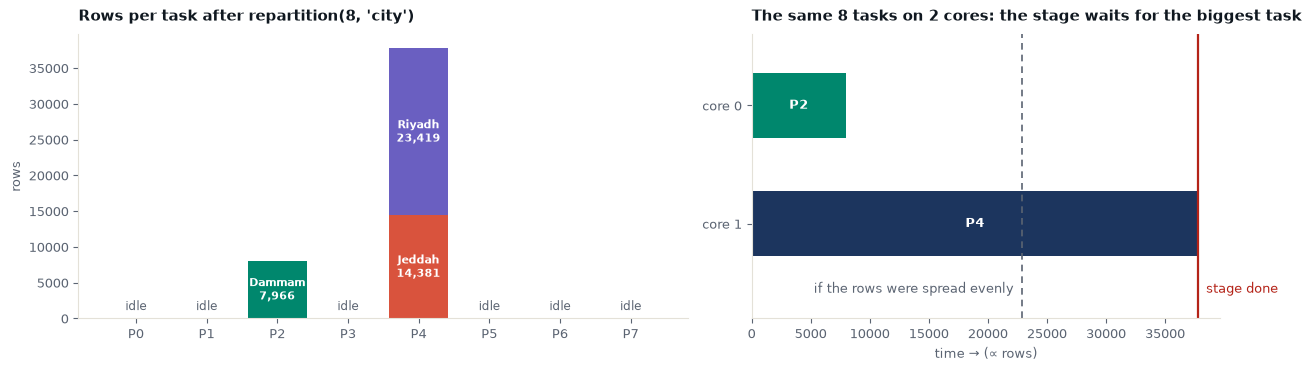

In [27]:
V.skew(skewed, cores=spark.sparkContext.defaultParallelism, n=8)

Three keys can keep at most three tasks busy. Here it's worse: Jeddah and Riyadh hash to the **same** partition, so one
task holds most of the orders while six tasks get nothing. The job finishes when that task finishes, and more executors
don't help: one partition is still one task.

Fixes: **AQE** (on by default) splits oversized partitions in sort-merge joins at run time; **salting** spreads one key
over several tasks; or pick a better key. Lab 3.2 measures skew on National Day and salts it.

In [28]:
print("AQE:", spark.conf.get("spark.sql.adaptive.enabled"),
      "| skew-join handling:", spark.conf.get("spark.sql.adaptive.skewJoin.enabled"))

AQE: true | skew-join handling: true


## 7 · Writing: one file per task

**The idea.** Executors write in parallel, so every task writes its own file. The number of files is the number of
tasks in the last stage, not something you choose directly.

🤔 We write `big_baskets` after spreading it over 6 partitions. How many Parquet files land in the folder?

files written: 6


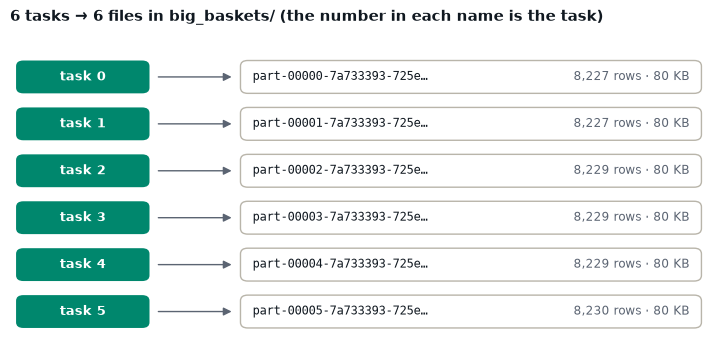

In [29]:
out = LAKE / "big_baskets"
big_baskets.repartition(6).write.mode("overwrite").parquet(out.as_posix())
print("files written:", U.count_files(out))
V.files(out)

Every task writes its own file. Add `partitionBy("day")` and each task writes one file **per folder it has rows for**:
1,000 tasks × 365 days = 365,000 small files. Lab 3.2 counts this and fixes it.

In [30]:
spark.stop()

## 8 · Back to the map

Spark **transforms** at scale: the same work as DuckDB or Polars, spread over a cluster.

In [31]:
V.platform_map(tool="spark")

| | |
|---|---|
| **It does** | DataFrame and SQL transformations over many machines · reads and writes Parquet, Iceberg and Delta tables · batch and streaming (Structured Streaming) · Python, SQL, Scala and Java on one engine |
| **It doesn't** | pay off on data one machine handles (start-up, shuffles and a cluster to run) · store tables itself (a table format does: `df.writeTo("cat.db.orders").append()`) · schedule its jobs (Dagster, Day 4) |
| **In this course** | Lab 3.2: one metric three ways, partition pruning, broadcast timing, salting, small files |
| **Managed equivalents** | Databricks, AWS EMR and Glue, Google Dataproc, Microsoft Fabric, Azure Synapse: Spark with the cluster run for you |
| **Neighbours** | DuckDB, Polars (one machine, often enough) · Trino (distributed SQL over a lake) · Flink (streaming first) · Ray, Dask (distributed Python) |

**Recap**

| We saw | Because |
|---|---|
| a driver plans, executors' cores run tasks | Spark splits the work over many machines |
| one task per partition, in waves over the cores | a partition on a core is a task |
| the transformations ran 0 jobs | transformations are lazy; actions run jobs |
| `groupBy` added an `Exchange`: all-to-all fetches | wide operations shuffle by key |
| `products` was broadcast, not shuffled | small side < `autoBroadcastJoinThreshold` |
| 2 of 8 tasks did all the work | one key → one task: skew |
| 6 partitions → 6 files | each task writes its own file |

## Checkpoint

1. A 40 GB daily job runs in DuckDB in 6 minutes. Should it move to Spark? What would change your answer?
2. Job, stage, task: which one does an action start, what starts a new stage, and what is one task?
3. Name two narrow and two wide operations. What does a wide one cost, and why?
4. A stage's 200 tasks finish in 30 s, but one runs for 40 minutes. What is the likely cause, and two fixes?
5. Why did 6 partitions write 6 files, and what happens with `partitionBy("day")` over a year?

**Next: [Lab 3.2 · Spark](../D3_2_spark.ipynb)**: one metric three ways (DataFrame API, SQL, DuckDB), partition
pruning, switching broadcast off and timing it, salting the hot day, and the small-files count with `partitionBy`.